In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

from PIL import Image
from pathlib import Path

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from ultralytics import YOLO

from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import pil_to_tensor, to_pil_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.7.1+cu128
TorchVision: 0.22.1+cu128
Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [2]:
IMAGE_PATH = 'images/01_image.png'

image = Image.open(IMAGE_PATH).convert("RGB")

print("Image loaded successfully!")
print("Image dimensions:", image.size)
print("Image format:", image.format)

Image loaded successfully!
Image dimensions: (1368, 912)
Image format: None


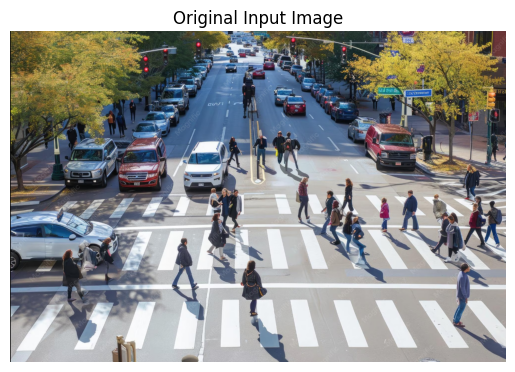

In [3]:
plt.imshow(image)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

# Faster R-CNN object detection

In [4]:
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

faster_rcnn = fasterrcnn_resnet50_fpn(
    weights= weights
)

faster_rcnn = faster_rcnn.to(device)
faster_rcnn.eval()

preprocess = weights.transforms()

categories = weights.meta["categories"]

print("Faster R-CNN loaded successfully!")
print("Number of COCO classes:", len(categories))
print("Running on:", device)

Faster R-CNN loaded successfully!
Number of COCO classes: 91
Running on: cuda


In [5]:
image_tensor = pil_to_tensor(image)

processed_image = preprocess(image)

processed_image = processed_image.to(device)

print("Original tensor shape:", image_tensor.shape)
print("Processed tensor shape:", processed_image.shape)
print("Device:", processed_image.device)

Original tensor shape: torch.Size([3, 912, 1368])
Processed tensor shape: torch.Size([3, 912, 1368])
Device: cuda:0


In [6]:
start_time = time.perf_counter()

with torch.inference_mode():

    prediction = faster_rcnn([processed_image])[0]

if device.type == 'cuda':
    torch.cuda.synchronize()

faster_rcnn_time = time.perf_counter() - start_time

print("Detection completed!")
print(f"Inference time: {faster_rcnn_time:.4f} seconds")

Detection completed!
Inference time: 0.6645 seconds


In [7]:
prediction.keys()

dict_keys(['boxes', 'labels', 'scores'])

In [8]:
 for label,score in zip(prediction['labels'].tolist(),prediction['scores'].tolist()):
     print(f'{categories[int(label)]:10} ---> {score:.2f}')

car        ---> 1.00
person     ---> 1.00
person     ---> 1.00
person     ---> 0.99
person     ---> 0.99
person     ---> 0.99
car        ---> 0.99
traffic light ---> 0.99
person     ---> 0.99
person     ---> 0.99
car        ---> 0.98
traffic light ---> 0.98
person     ---> 0.98
person     ---> 0.98
person     ---> 0.98
person     ---> 0.97
car        ---> 0.97
person     ---> 0.96
traffic light ---> 0.96
car        ---> 0.96
person     ---> 0.96
person     ---> 0.95
person     ---> 0.95
traffic light ---> 0.95
person     ---> 0.95
person     ---> 0.95
person     ---> 0.95
person     ---> 0.94
person     ---> 0.94
car        ---> 0.94
traffic light ---> 0.93
car        ---> 0.93
person     ---> 0.92
car        ---> 0.92
traffic light ---> 0.91
person     ---> 0.91
person     ---> 0.91
traffic light ---> 0.91
handbag    ---> 0.91
person     ---> 0.91
car        ---> 0.89
person     ---> 0.89
car        ---> 0.89
car        ---> 0.88
car        ---> 0.88
car        ---> 0.87
car        --

In [9]:
CONFIDENCE_THRESHOLD = 0.50

scores = prediction["scores"].cpu()
boxes = prediction["boxes"].cpu()
labels = prediction["labels"].cpu()

selected_indices = scores >= CONFIDENCE_THRESHOLD

filtered_boxes = boxes[selected_indices]
filtered_scores = scores[selected_indices]
filtered_labels = labels[selected_indices]

print("Objects detected:", len(filtered_boxes))

Objects detected: 81


In [10]:
faster_rcnn_results = []

for box, score, label in zip(
    filtered_boxes,
    filtered_scores,
    filtered_labels
):
    class_name = categories[int(label)]

    x1, y1, x2, y2 = box.tolist()

    faster_rcnn_results.append({
        "Object": class_name,
        "Confidence": round(float(score), 4),
        "X1": round(x1, 2),
        "Y1": round(y1, 2),
        "X2": round(x2, 2),
        "Y2": round(y2, 2)
    })

faster_rcnn_df = pd.DataFrame(faster_rcnn_results)

display(faster_rcnn_df)

,Object,Confidence,X1,Y1,X2,Y2
0,car,0.9985,0.34,494.32,299.39,656.10
1,person,0.9981,142.70,599.34,214.15,747.72
2,person,0.9971,635.40,633.12,708.31,781.38
3,person,0.9941,1074.88,435.50,1127.10,551.52
4,person,0.9924,789.76,401.23,830.89,527.25
...,...,...,...,...,...,...
76,car,0.5646,642.35,30.46,664.92,44.82
77,person,0.5480,246.93,556.20,288.63,691.19
78,handbag,0.5396,552.42,447.54,578.47,487.77
79,car,0.5342,476.28,297.85,613.26,443.36


In [11]:
if not faster_rcnn_df.empty:
    print("Object counts:")

    display(
        faster_rcnn_df["Object"]
        .value_counts()
        .rename_axis("Object")
        .reset_index(name="Count")
    )
else:
    print("No objects detected above the confidence threshold.")

Object counts:


,Object,Count
0,person,35
1,car,30
2,traffic light,9
3,handbag,4
4,truck,2
5,backpack,1


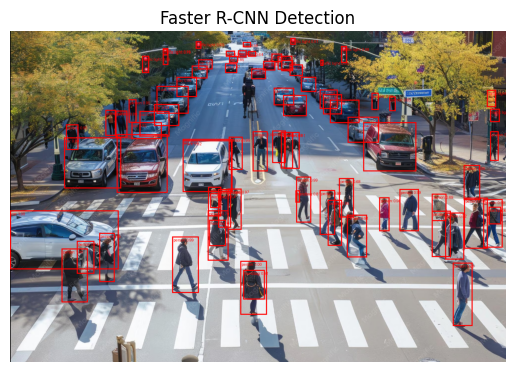

In [12]:
if len(filtered_boxes) > 0:

    box_labels = [
        f"{categories[int(label)]}: {float(score):.2f}"
        for label, score in zip(filtered_labels, filtered_scores)
    ]

    annotated_tensor = draw_bounding_boxes(
        image=image_tensor,
        boxes=filtered_boxes,
        labels=box_labels,
        colors="red",
        width=3
    )

    faster_rcnn_image = to_pil_image(annotated_tensor)

    plt.imshow(faster_rcnn_image)
    plt.title("Faster R-CNN Detection")
    plt.axis("off")
    plt.savefig('images/Faster R-CNN.jpg')
    plt.show()

else:
    faster_rcnn_image = image.copy()
    print("No bounding boxes to display.")

# YOLO object detection

In [13]:
yolo_model = YOLO("yolo26n.pt")

print("YOLO model loaded successfully!")
print("Model:", yolo_model.model_name if hasattr(yolo_model, "model_name") else "YOLO26n")

YOLO model loaded successfully!
Model: yolo26n.pt


In [14]:
start_time = time.perf_counter()

yolo_predictions = yolo_model.predict(
    source=IMAGE_PATH,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

yolo_time = time.perf_counter() - start_time

yolo_result = yolo_predictions[0]

print("YOLO detection completed!")
print(f"Inference time: {yolo_time:.4f} seconds")

YOLO detection completed!
Inference time: 0.2368 seconds


In [15]:
yolo_result

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'po

In [16]:
yolo_results = []

for box in yolo_result.boxes:

    class_id = int(box.cls.item())
    class_name = yolo_result.names[class_id]

    
    confidence = float(box.conf.item())

        
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    yolo_results.append({
        "Object": class_name,
        "Confidence": round(confidence, 4),
        "X1": round(x1, 2),
        "Y1": round(y1, 2),
        "X2": round(x2, 2),
        "Y2": round(y2, 2)
    })

yolo_df = pd.DataFrame(yolo_results)

display(yolo_df)

,Object,Confidence,X1,Y1,X2,Y2
0,person,0.6710,635.70,629.71,708.46,787.83
1,car,0.6355,750.91,178.64,817.25,234.15
2,car,0.6305,473.93,300.92,607.19,445.34
3,person,0.6287,443.38,569.55,520.83,720.32
4,person,0.5606,1220.10,639.20,1270.83,819.91
5,car,0.5128,294.67,287.85,433.73,441.75
6,traffic light,0.5054,362.17,64.75,385.63,125.25
7,truck,0.5037,977.11,253.42,1122.24,383.28
8,person,0.4964,143.04,601.89,208.43,745.58
9,truck,0.4766,143.50,295.30,301.11,433.76


In [17]:
if not yolo_df.empty:
    print("Object counts:")

    display(
        yolo_df["Object"]
        .value_counts()
        .rename_axis("Object")
        .reset_index(name="Count")
    )
else:
    print("No objects detected.")

Object counts:


,Object,Count
0,person,14
1,car,12
2,traffic light,3
3,truck,2


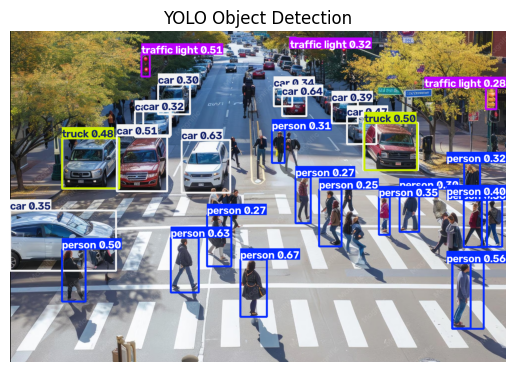

In [18]:
yolo_annotated = yolo_result.plot()

# Ultralytics returns a BGR image; Matplotlib expects RGB.
yolo_annotated = yolo_annotated[:, :, ::-1]

plt.imshow(yolo_annotated)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.savefig('images/yolo_detection.jpg')
plt.show()

In [19]:
comparison = pd.DataFrame({
    "Model": ["Faster R-CNN", "YOLO26n"],
    "Inference Time (seconds)": [
        faster_rcnn_time,
        yolo_time
    ],
    "Detected Objects": [
        len(faster_rcnn_df),
        len(yolo_df)
    ]
})

display(comparison)

,Model,Inference Time (seconds),Detected Objects
0,Faster R-CNN,0.664483,81
1,YOLO26n,0.236824,31


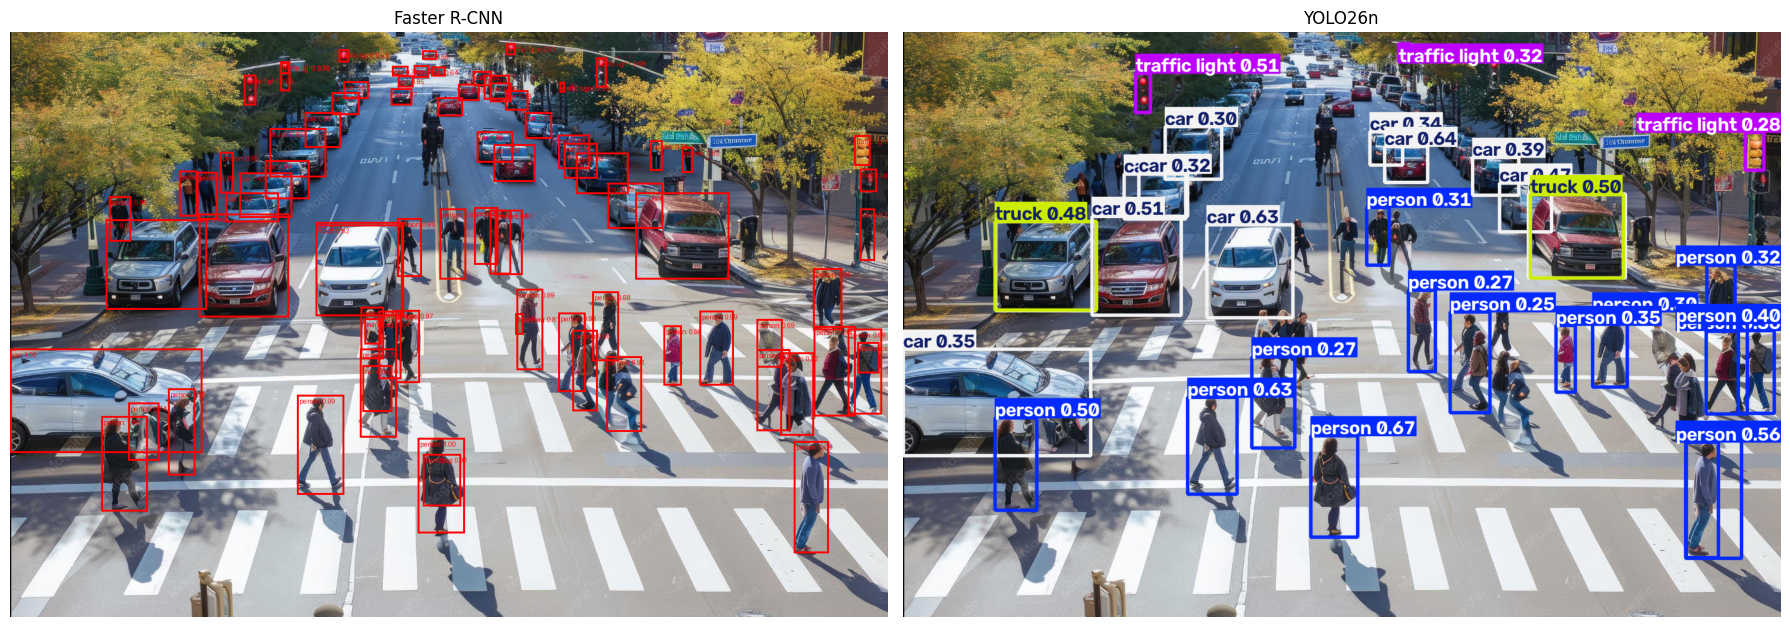

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(faster_rcnn_image)
axes[0].set_title("Faster R-CNN")
axes[0].axis("off")

axes[1].imshow(yolo_annotated)
axes[1].set_title("YOLO26n")
axes[1].axis("off")

plt.tight_layout()
plt.savefig('images/comparison.jpg')
plt.show()

In [21]:
comparison = pd.DataFrame({
    "Model": ["Faster R-CNN", "YOLO26n"],
    "Inference Time (seconds)": [
        faster_rcnn_time,
        yolo_time
    ],
    "Detected Objects": [
        len(faster_rcnn_df),
        len(yolo_df)
    ]
})

display(comparison)

,Model,Inference Time (seconds),Detected Objects
0,Faster R-CNN,0.664483,81
1,YOLO26n,0.236824,31
